**Mini Project – Machine Learning**
#### Name: Shreenidhi Thakur
#### Section: C
#### Batch: C2
#### Roll no.: 18

#### **Waveform Classification Using Machine Learning (Multiclass Classification Project)**
##### Project Introduction
##### 1. Real-world problem:
Signals such as sound, vibration and sensor readings are recorded as waveforms. Identifying which type of waveform a recording belongs to is useful in signal processing, fault detection and monitoring systems. A machine learning model can learn from labelled waveform samples and predict the class of a new sample.

##### 2. Aim
To classify waveform samples into three classes using machine learning classification algorithms and compare their performance.

##### 3. Dataset
UCI **Waveform Database Generator (Version 1)**: 5,000 records, 21 numerical input features and 3 target classes (0, 1, 2). Each class is generated from a combination of two out of three base waveforms, with noise added to every feature.

##### 4. Objectives
1. Load the dataset and inspect its structure and data quality.
2. Perform EDA using class counts, feature distributions and correlations.
3. Split the data into training and testing sets (stratified).
4. Train Decision Tree, KNN and SVM classifiers with default settings and evaluate them.
5. Tune each model using GridSearchCV (including the SVM kernel).
6. Evaluate the tuned models on the same held-out test set.
7. Compare default versus tuned performance using accuracy, precision, recall and F1-score.
8. Display confusion matrices and identify the best model.

##### Step 1: Import libraries
###### pandas/NumPy for data handling, Matplotlib/Seaborn for visualisation and scikit-learn for splitting, scaling, modelling and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

##### Step 2: Load the dataset
###### The original file **waveform.data.Z** (Version 1) is a compressed, headerless, comma-separated file with 22 columns (21 features + 1 class). It was decompressed and saved as **waveform.csv** with column names added: **feature_1** to **feature_21** and **class**.

In [2]:
df = pd.read_csv("waveform.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


##### Step 3: Exploratory Data Analysis (EDA)
###### EDA checks the size of the data, column types, missing values, duplicates and class balance before model training.

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (5000, 22)


In [4]:
print("First five rows:")
print(df.head())

First five rows:
   feature_1  feature_2  feature_3  ...  feature_20  feature_21  class
0      -1.23      -1.56      -1.75  ...        0.24       -0.56      2
1      -0.69       2.43       0.61  ...        0.60        2.42      1
2      -0.12      -0.94       1.29  ...       -0.79       -0.12      0
3       0.86       0.29       2.19  ...       -1.18        1.12      1
4       1.16       0.37       0.40  ...       -0.80       -0.68      1

[5 rows x 22 columns]


In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'class']


In [6]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   feature_1   5000 non-null   float64
 1   feature_2   5000 non-null   float64
 2   feature_3   5000 non-null   float64
 3   feature_4   5000 non-null   float64
 4   feature_5   5000 non-null   float64
 5   feature_6   5000 non-null   float64
 6   feature_7   5000 non-null   float64
 7   feature_8   5000 non-null   float64
 8   feature_9   5000 non-null   float64
 9   feature_10  5000 non-null   float64
 10  feature_11  5000 non-null   float64
 11  feature_12  5000 non-null   float64
 12  feature_13  5000 non-null   float64
 13  feature_14  5000 non-null   float64
 14  feature_15  5000 non-null   float64
 15  feature_16  5000 non-null   float64
 16  feature_17  5000 non-null   float64
 17  feature_18  5000 non-null   float64
 18  feature_19  5000 non-null   float64
 19  feature_20  5000 

In [7]:
print("Statistical summary:")
print(df.describe())

Statistical summary:
         feature_1    feature_2  ...   feature_21        class
count  5000.000000  5000.000000  ...  5000.000000  5000.000000
mean      0.005144     0.338746  ...    -0.021378     1.007800
std       1.010130     1.053657  ...     0.997064     0.818946
min      -3.340000    -3.250000  ...    -3.880000     0.000000
25%      -0.680000    -0.372500  ...    -0.690000     0.000000
50%       0.010000     0.340000  ...    -0.030000     1.000000
75%       0.690000     1.050000  ...     0.660000     2.000000
max       3.940000     3.880000  ...     4.010000     2.000000

[8 rows x 22 columns]


In [8]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
feature_1     0
feature_2     0
feature_3     0
feature_4     0
feature_5     0
feature_6     0
feature_7     0
feature_8     0
feature_9     0
feature_10    0
feature_11    0
feature_12    0
feature_13    0
feature_14    0
feature_15    0
feature_16    0
feature_17    0
feature_18    0
feature_19    0
feature_20    0
feature_21    0
class         0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


###### **Observation:** The dataset has 5,000 rows, 21 float input features (**feature_1** to **feature_21**) and one integer target column (**class**). There are no missing values and no duplicate rows, so no rows need to be removed.

Target class distribution
###### Class counts show whether the three classes are balanced. If they are, accuracy is a reliable metric.

In [10]:
print("Target distribution:")
print(df["class"].value_counts().sort_index())

Target distribution:
class
0    1657
1    1647
2    1696
Name: count, dtype: int64


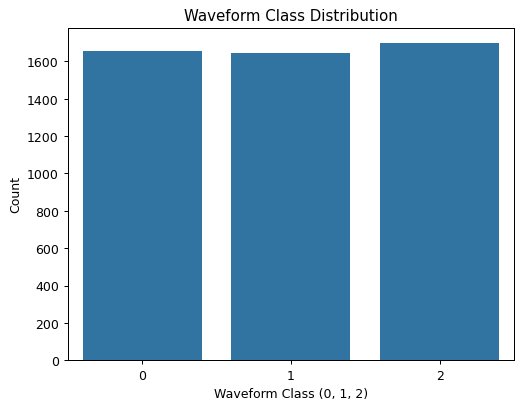

In [11]:
sns.countplot(data=df, x="class")

plt.title("Waveform Class Distribution")
plt.xlabel("Waveform Class (0, 1, 2)")
plt.ylabel("Count")
plt.show()

###### **Observation:** The three classes have almost the same number of records, so the dataset is balanced.

Distribution of selected features
###### Histograms of three example features show the spread of values. The features are numbered because the dataset has no feature names.

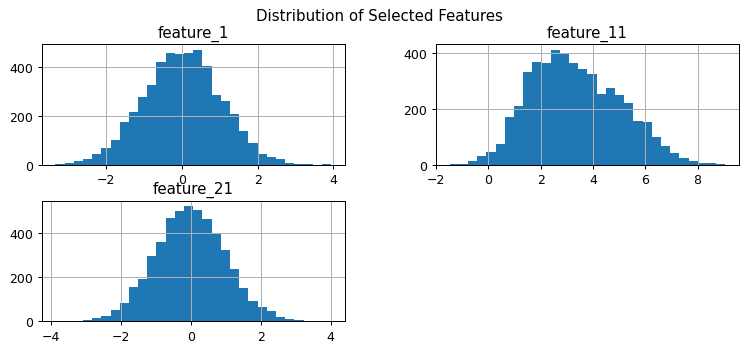

In [12]:
df[["feature_1", "feature_11", "feature_21"]].hist(figsize=(10, 4), bins=30)

plt.suptitle("Distribution of Selected Features")
plt.show()

###### **Observation:** The values are spread around a centre with a bell-like shape, which is expected because noise is added to every feature. The middle feature (**feature_11**) has a larger mean (about 3.3) and wider spread than the end features, whose values are centred near 0.

Box plots of selected features
###### Box plots show the median, spread and outliers of a feature for each class.

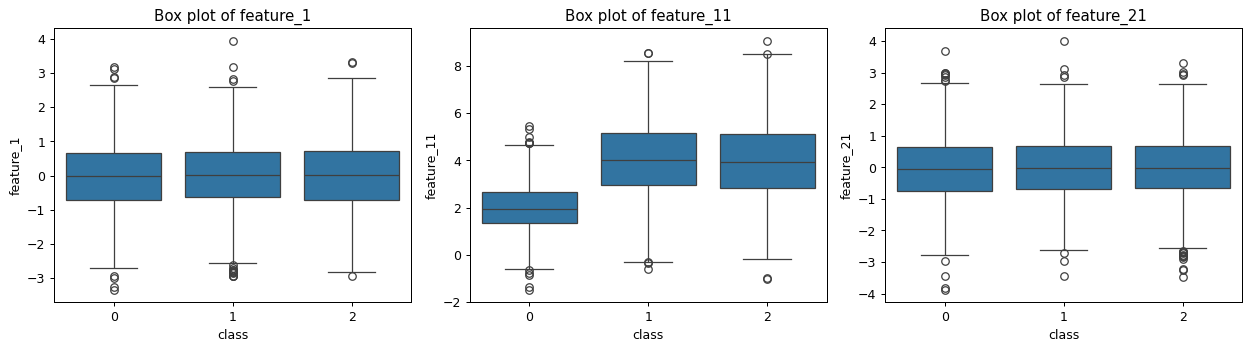

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, ["feature_1", "feature_11", "feature_21"]):
    sns.boxplot(data=df, x="class", y=col, ax=ax)
    ax.set_title("Box plot of " + col)

plt.tight_layout()
plt.show()

###### **Observation:** The median of **feature_11** is clearly lower for class 0 than for classes 1 and 2, so this feature helps to separate class 0 from the others, but not class 1 from class 2. The end features (**feature_1**, **feature_21**) look almost the same for all classes, so they carry little class information.

Correlation heatmap
###### The heatmap shows pairwise correlation between all 21 features and the class column. Correlation shows association, not causation.

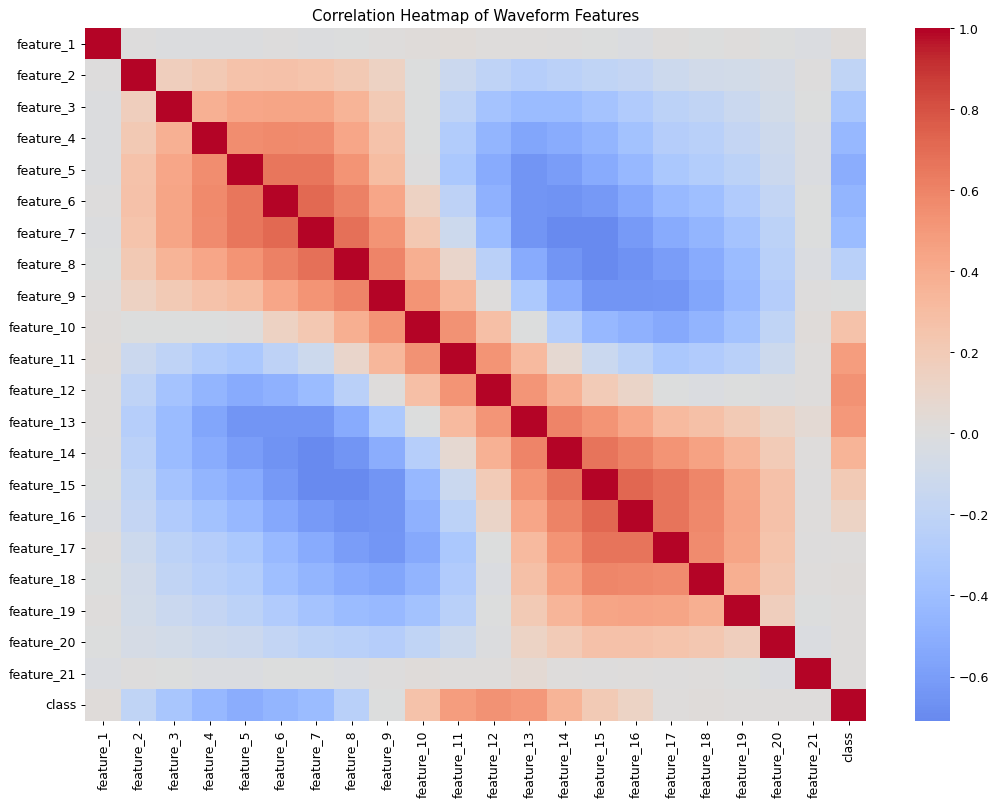

In [14]:
plt.figure(figsize=(14, 10))

correlation = df.corr()

sns.heatmap(correlation, cmap="coolwarm", center=0)

plt.title("Correlation Heatmap of Waveform Features")
plt.show()

###### **Observation:** Neighbouring features are positively correlated because they are consecutive points of the same waveform. Features that are far apart are only weakly correlated.

##### Step 4: Data preprocessing
###### All columns are numerical, there are no missing values and no duplicates, so no encoding, imputation or duplicate removal is needed. Only train/test splitting and scaling (for KNN and SVM) are required.

Separate features and target

In [15]:
X = df.drop("class", axis=1)
y = df["class"]  # input features (X) are used to predict the target (y)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5000, 21)
Target shape: (5000,)


Train Test Split
###### 80% of the data is used for training and 20% for testing. **stratify=y** keeps the class proportions the same in both sets. The same split is used for all three models.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 21)
Testing data: (1000, 21)


Feature scaling (for KNN and SVM)
###### KNN and SVM depend on distances between points, so features are standardised. The scaler is fitted **only on the training data** and then applied to the test data to avoid data leakage. The Decision Tree does not need scaling.

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling completed")

Scaling completed


##### Step 5: Decision Tree Classifier (default settings)
###### A decision tree learns rules by splitting on feature values. It uses the original (unscaled) features.

In [18]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree trained successfully")
print("Decision Tree Accuracy:", round(accuracy_score(y_test, dt_pred), 4))

Decision Tree trained successfully
Decision Tree Accuracy: 0.743


In [19]:
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.74      0.70      0.72       332
           1       0.73      0.76      0.74       329
           2       0.75      0.77      0.76       339

    accuracy                           0.74      1000
   macro avg       0.74      0.74      0.74      1000
weighted avg       0.74      0.74      0.74      1000



##### Step 6: K-Nearest Neighbors (KNN) Classifier (default settings)
###### KNN predicts the class of a sample by a majority vote of its K closest training samples. The default is **n_neighbors=5**. Scaled features are used.

In [20]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

print("KNN trained successfully")
print("KNN Accuracy:", round(accuracy_score(y_test, knn_pred), 4))

KNN trained successfully
KNN Accuracy: 0.812


In [21]:
print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

           0       0.87      0.70      0.78       332
           1       0.77      0.87      0.82       329
           2       0.81      0.86      0.83       339

    accuracy                           0.81      1000
   macro avg       0.82      0.81      0.81      1000
weighted avg       0.82      0.81      0.81      1000



##### Step 7: Support Vector Machine (SVM) Classifier (default settings)
###### SVM finds a decision boundary that separates the classes with the largest margin. The default **rbf** kernel is used first on scaled features.

In [22]:
svm_model = SVC(kernel="rbf")

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM trained successfully")
print("SVM Accuracy:", round(accuracy_score(y_test, svm_pred), 4))

SVM trained successfully
SVM Accuracy: 0.853


In [23]:
print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.87      0.78      0.82       332
           1       0.85      0.85      0.85       329
           2       0.84      0.93      0.88       339

    accuracy                           0.85      1000
   macro avg       0.85      0.85      0.85      1000
weighted avg       0.85      0.85      0.85      1000



##### Step 8: Initial performance of the default models
###### All three models are tested on the same test set. Because there are three classes, precision, recall and F1-score use **weighted averaging** (each class is weighted by the number of test samples it has).

In [24]:
default_predictions = {
    "Decision Tree": dt_pred,
    "KNN": knn_pred,
    "SVM": svm_pred
}

default_results = []

for name, y_pred in default_predictions.items():
    default_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-Score": f1_score(y_test, y_pred, average="weighted")
    })

default_df = pd.DataFrame(default_results)

print("Default Model Performance (weighted average):")
print(default_df.round(4))

Default Model Performance (weighted average):
           Model  Accuracy  Precision  Recall  F1-Score
0  Decision Tree     0.743     0.7430   0.743    0.7427
1            KNN     0.812     0.8177   0.812    0.8105
2            SVM     0.853     0.8540   0.853    0.8520


##### Step 9: Hyperparameter tuning using GridSearchCV
###### GridSearchCV tries every combination of the listed parameter values using 5-fold cross-validation on the **training data only** and keeps the combination with the best mean accuracy. The test set is not used for tuning, so it stays a fair held-out set. The best model is then refitted on the full training data.

Decision Tree tuning

In [25]:
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best parameters:", dt_grid.best_params_)
print("Best cross-validation accuracy:", round(dt_grid.best_score_, 4))

Best parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best cross-validation accuracy: 0.7665


KNN tuning
###### The number of neighbours, the voting type (**uniform** or **distance**) and the distance type (**p=1** Manhattan, **p=2** Euclidean) are tuned using the scaled training data.

In [26]:
knn_param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train_scaled, y_train)

print("Best parameters:", knn_grid.best_params_)
print("Best cross-validation accuracy:", round(knn_grid.best_score_, 4))

Best parameters: {'n_neighbors': 31, 'p': 1, 'weights': 'distance'}
Best cross-validation accuracy: 0.8532


SVM tuning
###### The **kernel** is tuned along with **C** (strictness of the margin) and **gamma** (reach of a single training point). **gamma** is used by the **rbf** and **poly** kernels only; the **linear** kernel ignores it.

In [27]:
svm_param_grid = {
    "kernel": ["linear", "rbf", "poly"],
    "C": [0.01, 0.1, 1, 10],
    "gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    estimator=SVC(),
    param_grid=svm_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

print("Best parameters:", svm_grid.best_params_)
print("Best cross-validation accuracy:", round(svm_grid.best_score_, 4))

Best parameters: {'C': 0.01, 'gamma': 'scale', 'kernel': 'linear'}
Best cross-validation accuracy: 0.8715


###### **Note:** The scaler was fitted on the full training set before cross-validation (the same simple approach used in the reference notebooks). The held-out test set was never used for fitting the scaler or for tuning.

##### Step 10: Evaluate the tuned models on the test set
###### The best estimator found by each grid search is used to predict the same test set.

In [28]:
tuned_dt = dt_grid.best_estimator_
tuned_knn = knn_grid.best_estimator_
tuned_svm = svm_grid.best_estimator_

tuned_dt_pred = tuned_dt.predict(X_test)
tuned_knn_pred = tuned_knn.predict(X_test_scaled)
tuned_svm_pred = tuned_svm.predict(X_test_scaled)

print("Tuned Decision Tree Accuracy:", round(accuracy_score(y_test, tuned_dt_pred), 4))
print("Tuned KNN Accuracy:", round(accuracy_score(y_test, tuned_knn_pred), 4))
print("Tuned SVM Accuracy:", round(accuracy_score(y_test, tuned_svm_pred), 4))

Tuned Decision Tree Accuracy: 0.755
Tuned KNN Accuracy: 0.834
Tuned SVM Accuracy: 0.857


In [29]:
print("Tuned Decision Tree")
print(classification_report(y_test, tuned_dt_pred))

Tuned Decision Tree
              precision    recall  f1-score   support

           0       0.77      0.69      0.73       332
           1       0.73      0.77      0.75       329
           2       0.77      0.80      0.78       339

    accuracy                           0.76      1000
   macro avg       0.76      0.75      0.75      1000
weighted avg       0.76      0.76      0.75      1000



In [30]:
print("Tuned KNN")
print(classification_report(y_test, tuned_knn_pred))

Tuned KNN
              precision    recall  f1-score   support

           0       0.91      0.70      0.79       332
           1       0.81      0.88      0.84       329
           2       0.81      0.92      0.86       339

    accuracy                           0.83      1000
   macro avg       0.84      0.83      0.83      1000
weighted avg       0.84      0.83      0.83      1000



In [31]:
print("Tuned SVM")
print(classification_report(y_test, tuned_svm_pred))

Tuned SVM
              precision    recall  f1-score   support

           0       0.88      0.78      0.83       332
           1       0.85      0.85      0.85       329
           2       0.84      0.93      0.89       339

    accuracy                           0.86      1000
   macro avg       0.86      0.86      0.86      1000
weighted avg       0.86      0.86      0.86      1000



##### Step 11: Comparison of default and tuned models
###### The table lists the test results of all six models (three default and three tuned). Each model is evaluated on the same test set using weighted averaging.

In [32]:
tuned_predictions = {
    "Decision Tree (Tuned)": tuned_dt_pred,
    "KNN (Tuned)": tuned_knn_pred,
    "SVM (Tuned)": tuned_svm_pred
}

tuned_results = []

for name, y_pred in tuned_predictions.items():
    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-Score": f1_score(y_test, y_pred, average="weighted")
    })

tuned_df = pd.DataFrame(tuned_results)

default_df["Model"] = default_df["Model"] + " (Default)"

results_df = pd.concat([default_df, tuned_df], ignore_index=True)

print("Default vs Tuned Model Comparison (weighted average):")
print(results_df.round(4))

Default vs Tuned Model Comparison (weighted average):
                     Model  Accuracy  Precision  Recall  F1-Score
0  Decision Tree (Default)     0.743     0.7430   0.743    0.7427
1            KNN (Default)     0.812     0.8177   0.812    0.8105
2            SVM (Default)     0.853     0.8540   0.853    0.8520
3    Decision Tree (Tuned)     0.755     0.7557   0.755    0.7544
4              KNN (Tuned)     0.834     0.8417   0.834    0.8318
5              SVM (Tuned)     0.857     0.8584   0.857    0.8560


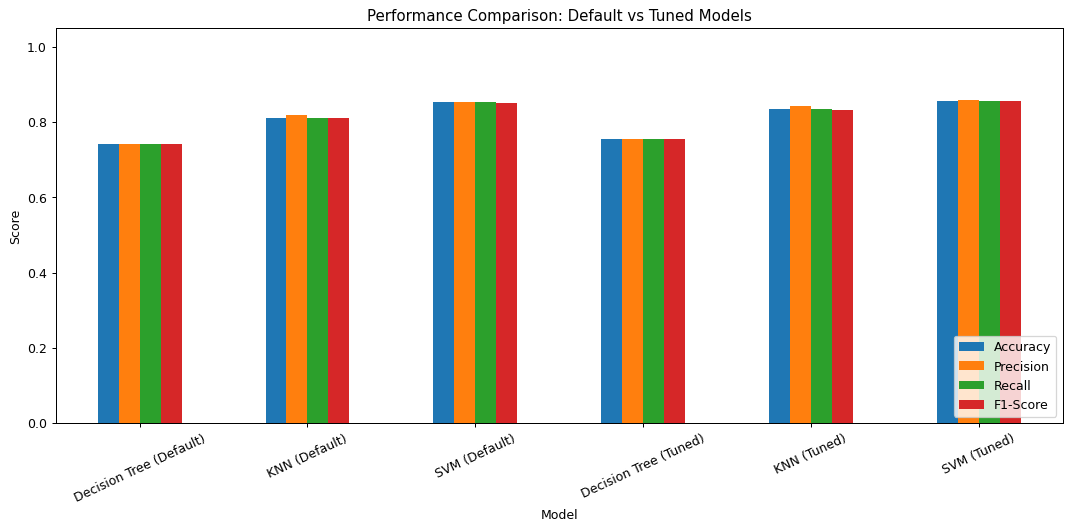

In [33]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Performance Comparison: Default vs Tuned Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Change in accuracy after tuning

In [34]:
change = pd.DataFrame({
    "Default Accuracy": default_df["Accuracy"].values,
    "Tuned Accuracy": tuned_df["Accuracy"].values
}, index=["Decision Tree", "KNN", "SVM"])

change["Change"] = change["Tuned Accuracy"] - change["Default Accuracy"]

print(change.round(4))

               Default Accuracy  Tuned Accuracy  Change
Decision Tree             0.743           0.755   0.012
KNN                       0.812           0.834   0.022
SVM                       0.853           0.857   0.004


Best-performing model

In [35]:
best_model = results_df.loc[results_df["F1-Score"].idxmax()]

print("Best model based on F1-score:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-score:", round(best_model["F1-Score"], 4))

Best model based on F1-score: SVM (Tuned)
Accuracy: 0.857
Precision: 0.8584
Recall: 0.857
F1-score: 0.856


##### Step 12: Confusion matrices
###### Rows are the actual classes and columns are the predicted classes. Numbers on the diagonal are correct predictions; numbers off the diagonal show which classes the model confuses. The top row shows the default models and the bottom row shows the tuned models.

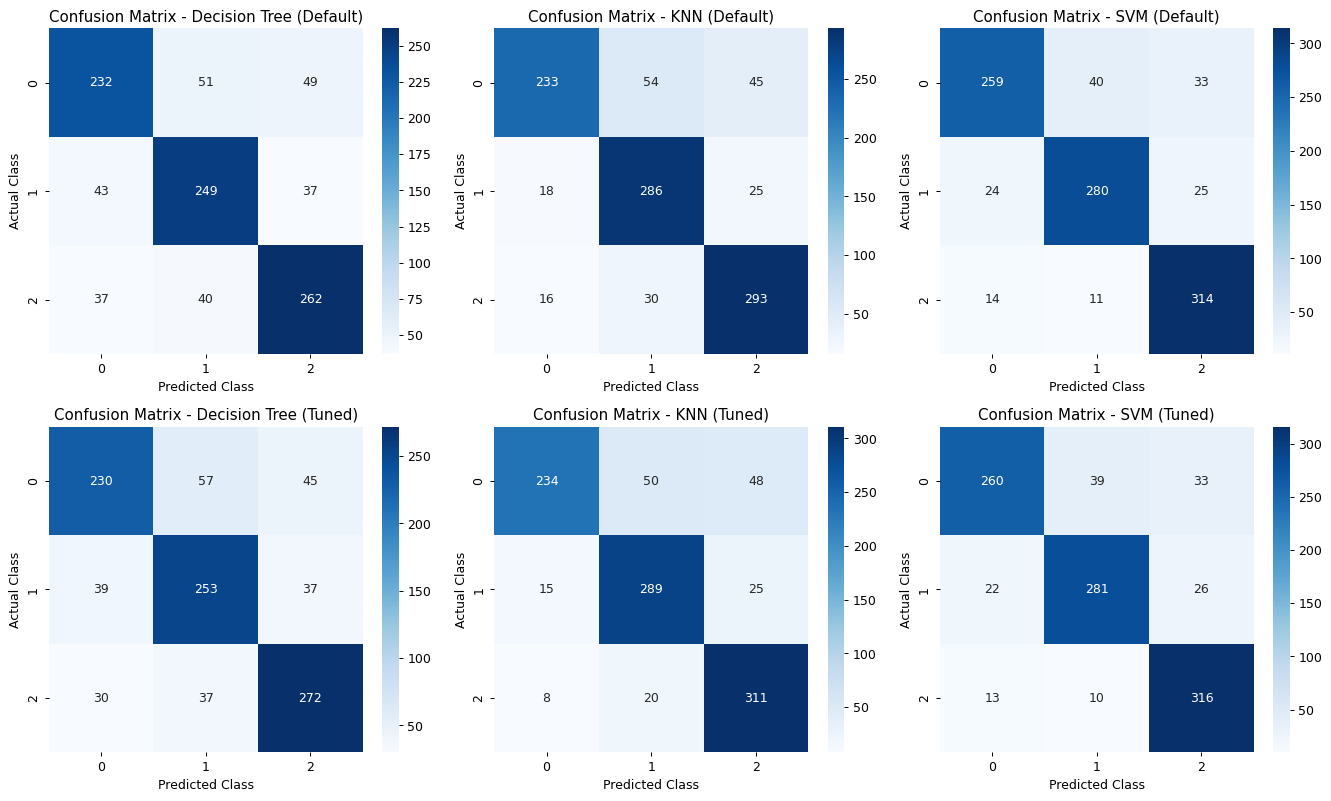

In [36]:
all_predictions = {
    "Decision Tree (Default)": dt_pred,
    "KNN (Default)": knn_pred,
    "SVM (Default)": svm_pred,
    "Decision Tree (Tuned)": tuned_dt_pred,
    "KNN (Tuned)": tuned_knn_pred,
    "SVM (Tuned)": tuned_svm_pred
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, y_pred) in zip(axes.flatten(), all_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title("Confusion Matrix - " + name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

###### **Observation:** The diagonal values show correct predictions for classes 0, 1 and 2. Comparing the off-diagonal values across the models shows which model makes fewer mistakes and between which classes the mistakes happen.

##### Step 13: Conclusion

###### 1. Objective and dataset
The aim was to classify waveform samples into three classes and compare machine learning algorithms. The UCI Waveform Database Generator (Version 1) dataset was used: 5,000 records, 21 numerical features and 3 balanced classes, with no missing values and no duplicate rows.

###### 2. Workflow summary
1. Loaded the data (decompressed from **waveform.data.Z** to **waveform.csv**) and performed EDA.
2. Made one stratified 80:20 train/test split used by every model.
3. Scaled the features with **StandardScaler** (fitted on training data only) for KNN and SVM.
4. Trained **Decision Tree**, **KNN** and **SVM** with default settings and evaluated them on the test set.
5. Tuned each model with **GridSearchCV** (5-fold cross-validation on the training data), including the SVM **kernel**, and evaluated the tuned models on the same test set.

###### 3. Best parameters found
| Model | Best parameters |
|---|---|
| Decision Tree | criterion = gini, max_depth = 10, min_samples_split = 5, min_samples_leaf = 1 |
| KNN | n_neighbors = 31, weights = distance, p = 1 (Manhattan) |
| SVM | kernel = linear, C = 0.01, gamma = scale (not used by the linear kernel) |

###### 4. Results (test set, 1,000 samples, weighted averages)
| Model | Accuracy | Precision | Recall | F1-Score |
|---|---|---|---|---|
| Decision Tree (Default) | 0.743 | 0.743 | 0.743 | 0.743 |
| KNN (Default) | 0.812 | 0.818 | 0.812 | 0.811 |
| SVM (Default) | 0.853 | 0.854 | 0.853 | 0.852 |
| Decision Tree (Tuned) | 0.755 | 0.756 | 0.755 | 0.754 |
| KNN (Tuned) | 0.834 | 0.842 | 0.834 | 0.832 |
| **SVM (Tuned)** | **0.857** | **0.858** | **0.857** | **0.856** |

The **tuned SVM** performed best on every metric.

###### 5. What was learned
- Tuning improved all three models on the test set: accuracy rose by about 0.012 for the Decision Tree, 0.022 for KNN and only 0.004 for SVM. The SVM was already good with default settings.
- SVM and KNN, which use scaled features and distances, did better than the single Decision Tree, which fits the noise in the data more easily.
- For the SVM, the linear kernel with a small **C** beat the **rbf** and **poly** kernels in cross-validation. A strongly regularised linear boundary works well here, probably because noise is added to every feature.
- The confusion matrices show which classes each model confuses, which accuracy alone does not show.

###### 6. Limitations
- Results depend on one train/test split. The tuned SVM's gain over its default (0.004, about 4 test samples) is small and may not be meaningful.
- The best KNN **n_neighbors** and SVM **C** values were near the edge of the grids searched, so a wider grid might change them slightly.
- The features are numbered only, so they cannot be interpreted physically.